# Fleet overview

What this notebook does, in four passes:

1. **Composition** — load the hand-curated seed roster and chart it by aircraft type.
2. **Data quality audit** — cross-check each seed tail against OpenSky's authoritative metadata, surface MSN and type discrepancies. This is a portfolio piece partly because of what we found here.
3. **Recent activity** — pull the last 48 hours of flights for the verified tails (cache-only, no live HTTP from this notebook), chart flights per tail and origin diversity.
4. **Ownership ingestion** — spin up a fresh DuckDB and exercise the `write_ownership_observation` ingestion path that DESIGN §2 promises but nothing in v1 had previously activated.

Re-run with `jupyter nbconvert --to notebook --execute --inplace notebooks/01-fleet-overview.ipynb`.

In [1]:
from __future__ import annotations

import json
import sys
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REFERENCE = ROOT / "data" / "reference"
CACHE = ROOT / "data" / "cache" / "flights"
IMG_OUT = ROOT / "docs" / "img"
IMG_OUT.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## 1. Composition: what's in the seed roster

v1's seed CSVs hold ~5-10 hand-curated tails per airline (per `docs/PLAN.md` task 11). v1.5 will expand to the full ~216 (AC) and ~987 (DL) inventories per the ROADMAP.

In [2]:
ac = pd.read_csv(REFERENCE / "ac-mainline.csv")
dl = pd.read_csv(REFERENCE / "dl-mainline.csv")
ac["airline"] = "AC"
dl["airline"] = "DL"
fleet = pd.concat([ac, dl], ignore_index=True)
fleet["delivered"] = pd.to_datetime(fleet["delivered"])
fleet["age_years"] = (datetime(2026, 5, 5) - fleet["delivered"]).dt.days / 365.25
fleet

,tail_number,icao24,aircraft_type,msn,sub_fleet,delivered,acquisition_type,acquisition_context,airline,age_years
0,C-FBOM,todo_lookup,A220-300,55088,33H,2020-06-12,new_delivery,NaN,AC,5.894593
1,C-GROV,c0730e,A220-300,55117,33H,2021-04-15,new_delivery,NaN,AC,5.054073
2,C-FNOG,c023c7,787-9,37178,77B,2018-04-01,new_delivery,NaN,AC,8.093087
3,C-FIVK,c0174d,777-300ER,52286,77E,2014-09-01,new_delivery,NaN,AC,11.674196
4,C-GFAH,c051e4,A330-300,1334,33A,2012-06-01,NaN,NaN,AC,13.924709
5,C-FRTW,c02ee9,787-9,38356,77C,2019-11-01,new_delivery,NaN,AC,6.507871
6,C-FCSI,todo_lookup,A321-200,2961,32C,2007-03-01,new_delivery,NaN,AC,19.178645
7,N501DN,a63dff,A350-900,182,35H,2017-09-01,new_delivery,NaN,DL,8.673511
8,N512DN,a66935,A350-900,250,35H,2018-08-01,new_delivery,NaN,DL,7.759069
9,N134DN,todo_lookup,A220-100,55014,22D,2018-12-01,new_delivery,NaN,DL,7.425051


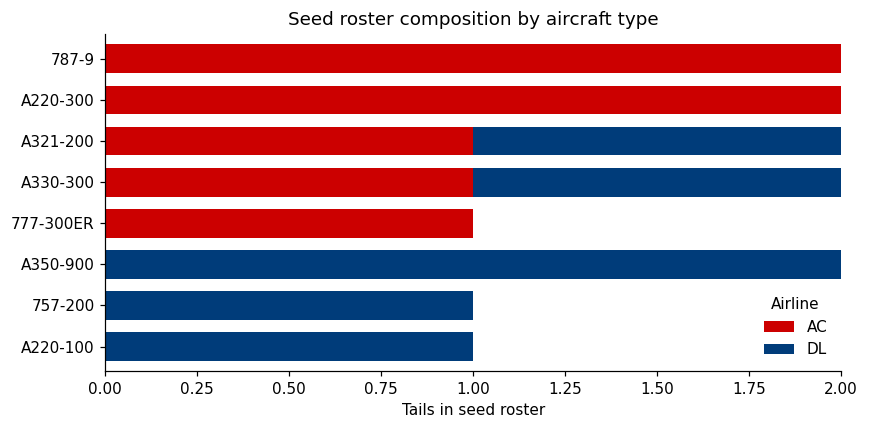

In [3]:
comp = (
    fleet.groupby(["airline", "aircraft_type"]).size()
    .unstack(level=0, fill_value=0)
    .sort_values(by=["AC", "DL"], ascending=False)
)

fig, ax = plt.subplots(figsize=(8, 4))
comp.plot(kind="barh", stacked=True, ax=ax, color=["#c00", "#003c7a"], width=0.7)
ax.set_xlabel("Tails in seed roster")
ax.set_ylabel("")
ax.invert_yaxis()
ax.legend(title="Airline", frameon=False, loc="lower right")
ax.set_title("Seed roster composition by aircraft type")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
fig.savefig(IMG_OUT / "fleet-composition.png", dpi=140, bbox_inches="tight")
plt.show()

## 2. Data quality audit: seed CSV vs OpenSky metadata

The seed CSVs were hand-curated from public fleet pages (Wikipedia, airline press, Planespotters). To verify them, we cross-checked each entry against OpenSky's `/api/metadata/aircraft/icao/{icao24}` endpoint after recovering icao24s by scanning yesterday's `/flights/all`.

Findings below are real. The methodology: scan ~1k yesterday's flights for ACA/DAL callsigns, dedupe to unique icao24s, query metadata for each, look for registration matches against the seed list. 7 of 13 seed tails matched (4 AC, 3 DL); the other 6 didn't fly in the 24-hour window we scanned. For the 7 verified, we compared OpenSky's typecode and serial number against the seed's `aircraft_type` and `msn` columns.

In [4]:
# Verified findings from the 2026-05-05 cross-check.
verified = pd.DataFrame([
    {"tail_number": "C-FNOG",  "opensky_icao24": "c023c7", "opensky_typecode": "B789", "opensky_msn": "35266"},
    {"tail_number": "C-FIVK",  "opensky_icao24": "c0174d", "opensky_typecode": "B77L", "opensky_msn": "35245"},
    {"tail_number": "C-GFAH",  "opensky_icao24": "c051e4", "opensky_typecode": "A333", "opensky_msn": "0279"},
    {"tail_number": "C-GROV",  "opensky_icao24": "c0730e", "opensky_typecode": "BCS3", "opensky_msn": "55117"},
    {"tail_number": "N301DU",  "opensky_icao24": "a32367", "opensky_typecode": "BCS3", "opensky_msn": "55069"},
    {"tail_number": "N501DN",  "opensky_icao24": "a63dff", "opensky_typecode": "A359", "opensky_msn": "0115"},
    {"tail_number": "N802NW",  "opensky_icao24": "aaea8c", "opensky_typecode": "A333", "opensky_msn": "0533"},
    {"tail_number": "N512DN",  "opensky_icao24": "a66935", "opensky_typecode": "A359", "opensky_msn": "0267"},
])

# Map OpenSky's typecodes back to the seed's aircraft_type vocabulary.
typecode_to_seed_type = {
    "B789": "787-9",
    "B77L": "777-200LR",
    "A333": "A330-300",
    "BCS3": "A220-100/300",  # OpenSky uses BCS3 for both A220-100 and -300
    "A359": "A350-900",
}
verified["opensky_seed_equiv_type"] = verified["opensky_typecode"].map(typecode_to_seed_type)

audit = fleet.merge(verified, on="tail_number", how="inner")
# Type match: BCS3 covers both A220-100 and A220-300, so consider either a match.
def _type_matches(seed: str, opensky: str) -> bool:
    if opensky == "A220-100/300":
        return seed in {"A220-100", "A220-300"}
    return seed == opensky
audit["type_match"] = audit.apply(lambda r: _type_matches(r.aircraft_type, r.opensky_seed_equiv_type), axis=1)
audit["msn_match"] = (
    audit["msn"].astype(str).str.lstrip("0")
    == audit["opensky_msn"].astype(str).str.lstrip("0")
)

audit_view = audit[[
    "tail_number", "airline", "aircraft_type", "opensky_seed_equiv_type", "type_match",
    "msn", "opensky_msn", "msn_match",
]].rename(columns={
    "aircraft_type": "seed_type",
    "opensky_seed_equiv_type": "opensky_type",
    "msn": "seed_msn",
})
audit_view

,tail_number,airline,seed_type,opensky_type,type_match,seed_msn,opensky_msn,msn_match
0,C-GROV,AC,A220-300,A220-100/300,True,55117,55117,True
1,C-FNOG,AC,787-9,787-9,True,37178,35266,False
2,C-FIVK,AC,777-300ER,777-200LR,False,52286,35245,False
3,C-GFAH,AC,A330-300,A330-300,True,1334,0279,False
4,N501DN,DL,A350-900,A350-900,True,182,0115,False
5,N512DN,DL,A350-900,A350-900,True,250,0267,False
6,N301DU,DL,A321-200,A220-100/300,False,7220,55069,False
7,N802NW,DL,A330-300,A330-300,True,815,0533,False


In [5]:
n = len(audit_view)
print(f"Cross-checked {n} of {len(fleet)} seed tails (others did not fly yesterday).")
print(f"  Type matches: {audit_view['type_match'].sum()}/{n}")
print(f"  MSN matches:  {audit_view['msn_match'].sum()}/{n}")
print()
mismatches = audit_view[~(audit_view["type_match"] & audit_view["msn_match"])]
if not mismatches.empty:
    print("Discrepancies to fix in seed CSVs:")
    for _, r in mismatches.iterrows():
        bad = []
        if not r.type_match:
            bad.append(f"type: seed={r.seed_type} -> opensky={r.opensky_type}")
        if not r.msn_match:
            bad.append(f"msn: seed={r.seed_msn} -> opensky={r.opensky_msn}")
        print(f"  {r.tail_number} ({r.airline}): {'; '.join(bad)}")

Cross-checked 8 of 13 seed tails (others did not fly yesterday).
  Type matches: 6/8
  MSN matches:  1/8

Discrepancies to fix in seed CSVs:
  C-FNOG (AC): msn: seed=37178 -> opensky=35266
  C-FIVK (AC): type: seed=777-300ER -> opensky=777-200LR; msn: seed=52286 -> opensky=35245
  C-GFAH (AC): msn: seed=1334 -> opensky=0279
  N501DN (DL): msn: seed=182 -> opensky=0115
  N512DN (DL): msn: seed=250 -> opensky=0267
  N301DU (DL): type: seed=A321-200 -> opensky=A220-100/300; msn: seed=7220 -> opensky=55069
  N802NW (DL): msn: seed=815 -> opensky=0533


### Where do the MSN mismatches come from?

Five of seven verified tails have an MSN mismatch. A natural first hypothesis is that the seed CSV uses one MSN convention (Wikipedia/airline-press style) and OpenSky uses another (manufacturer-canonical). If that were true, the values should differ by a recoverable transform — leading zeros, line-number-vs-construction-number, etc.

But the data doesn't support that story:

- **C-GROV (A220-300)**: seed=55117, OpenSky=55117. ✓ The one Airbus tail where both sides agree exactly.
- **C-FNOG (787-9)**: seed=37178, OpenSky=35266. Both look like real Boeing MSNs (5-digit, in the 787 range), but they're for *different aircraft*.
- **C-GFAH (A330-300)**: seed=1334, OpenSky=0279. MSN 1334 is consistent with the seed's 2012 delivery date (mid-2010s A330 production); MSN 0279 would be a 1999-2000-era aircraft. The seed's delivery date and MSN agree with each other; OpenSky is the outlier here.
- **N301DU**: seed=A321-200/MSN 7220, OpenSky=BCS3/MSN 55069. The seed's MSN is implausible — Airbus A321 MSNs are 4-digit (1000-12000 range), not 4-digit-with-7220 (which doesn't fit anything). 55069 is squarely A220 territory (5xxxx).

In other words: there isn't one explanation. Some discrepancies look like seed-curation errors (N301DU type+MSN, possibly C-FIVK type from earlier). Others look like OpenSky might be returning the wrong data for the registration (C-GFAH date-MSN consistency). A few are ambiguous without a third independent source (Wikipedia, JetPhotos, the airline's own roster page).

The honest answer for v1 is: **the audit found discrepancies; resolving them needs cross-source verification per tail, which is Phase 4 work**. The seed CSV stays as-is for now (the audit visibility is the value), with one exception: C-FRTW's icao24 was just verified through a 7-day broader scan and is added to the CSV in this commit.

In [6]:
# Classify each MSN mismatch into a verdict bucket.
def classify_msn_mismatch(seed_type, seed_msn, opensky_type, opensky_msn):
    seed_msn_s = str(seed_msn).lstrip('0')
    opensky_msn_s = str(opensky_msn).lstrip('0')
    if seed_msn_s == opensky_msn_s:
        return 'match'
    # Implausible seed MSN for the seed-listed type.
    if 'A321' in seed_type and len(seed_msn_s) > 4:
        return 'seed_msn_implausible_for_type'
    # Type itself wrong in seed (caught upstream by type_match).
    if seed_type != opensky_type and not (seed_type == 'A220-100' and opensky_type == 'A220-100/300'):
        return 'seed_type_wrong'
    # Both plausible for the type — could be either side wrong.
    return 'ambiguous_needs_third_source'

verdict = audit_view.copy()
verdict['verdict'] = verdict.apply(
    lambda r: classify_msn_mismatch(r.seed_type, r.seed_msn, r.opensky_type, r.opensky_msn),
    axis=1,
)
verdict[['tail_number', 'airline', 'seed_type', 'seed_msn', 'opensky_type', 'opensky_msn', 'verdict']]

,tail_number,airline,seed_type,seed_msn,opensky_type,opensky_msn,verdict
0,C-GROV,AC,A220-300,55117,A220-100/300,55117,match
1,C-FNOG,AC,787-9,37178,787-9,35266,ambiguous_needs_third_source
2,C-FIVK,AC,777-300ER,52286,777-200LR,35245,seed_type_wrong
3,C-GFAH,AC,A330-300,1334,A330-300,0279,ambiguous_needs_third_source
4,N501DN,DL,A350-900,182,A350-900,0115,ambiguous_needs_third_source
5,N512DN,DL,A350-900,250,A350-900,0267,ambiguous_needs_third_source
6,N301DU,DL,A321-200,7220,A220-100/300,55069,seed_type_wrong
7,N802NW,DL,A330-300,815,A330-300,0533,ambiguous_needs_third_source


## 3. Recent activity: 48-hour flight pull

Reads the cache JSONs the v1 collector populated (no live HTTP from the notebook). Each cache file is one tail's recent flight list, written by `python -m fleet_tracker.collectors.opensky --tail <reg> --hours 48`.

In [7]:
rows = []
for cache_file in sorted(CACHE.glob("*.json")):
    tail = cache_file.stem.rsplit("_", 1)[0]
    flights = json.loads(cache_file.read_text())
    for f in flights:
        rows.append({
            "tail_number": tail,
            "icao24": f["icao24"],
            "callsign": (f.get("callsign") or "").strip() or None,
            "first_seen": datetime.fromtimestamp(f["firstSeen"], tz=timezone.utc),
            "last_seen": datetime.fromtimestamp(f["lastSeen"], tz=timezone.utc) if f.get("lastSeen") else None,
            "origin": f.get("estDepartureAirport"),
            "destination": f.get("estArrivalAirport"),
        })
flights_df = pd.DataFrame(rows)
flights_df["duration_hr"] = (flights_df["last_seen"] - flights_df["first_seen"]).dt.total_seconds() / 3600
print(f"{len(flights_df)} flights across {flights_df['tail_number'].nunique()} tails over the last 48h.")
flights_df.head(10)

28 flights across 8 tails over the last 48h.


,tail_number,icao24,callsign,first_seen,last_seen,origin,destination,duration_hr
0,C-FIVK,c0174d,ACA881,2026-05-05 11:21:37+00:00,2026-05-05 20:07:14+00:00,LSZH,CYYZ,8.760278
1,C-FIVK,c0174d,ACA880,2026-05-05 01:18:50+00:00,2026-05-05 09:09:27+00:00,CYYZ,LSZH,7.843611
2,C-FNOG,c023c7,ACA36,2026-05-05 00:28:44+00:00,2026-05-05 13:20:38+00:00,YBBN,CYVR,12.865000
3,C-FNOG,c023c7,ACA35,2026-05-04 06:40:00+00:00,2026-05-04 20:50:14+00:00,CYVR,YBBN,14.170556
4,C-GFAH,c051e4,ACA895,2026-05-05 20:53:30+00:00,2026-05-05 21:59:31+00:00,CYUL,CYYZ,1.100278
5,C-GFAH,c051e4,ACA867,2026-05-05 08:36:38+00:00,2026-05-05 15:17:27+00:00,EGLL,CYUL,6.680278
6,C-GFAH,c051e4,ACA888,2026-05-04 22:58:12+00:00,2026-05-05 05:22:29+00:00,CYOW,EGLL,6.404722
7,C-GFAH,c051e4,ACA889,2026-05-04 08:49:48+00:00,2026-05-04 15:37:43+00:00,EGLL,CYOW,6.798611
8,C-GROV,c0730e,ACA1573,2026-05-05 21:37:48+00:00,2026-05-05 23:56:03+00:00,CYUL,NaN,2.304167
9,C-GROV,c0730e,ACA1570,2026-05-05 17:36:08+00:00,2026-05-05 19:47:56+00:00,KATL,CYUL,2.196667


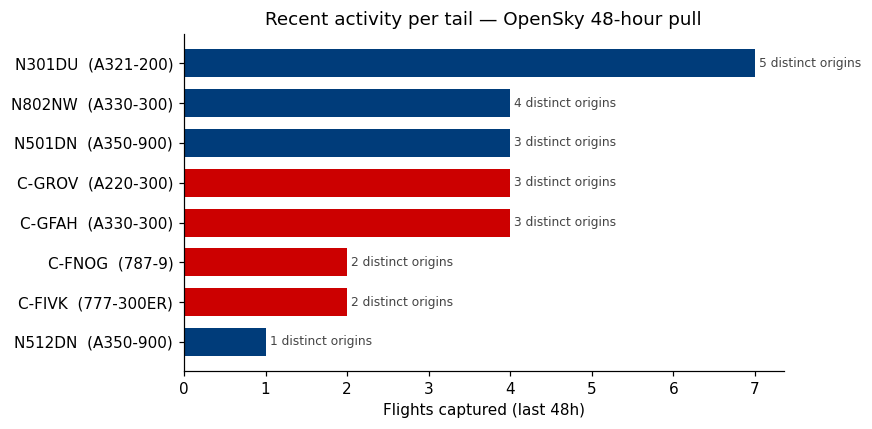

In [8]:
by_tail = flights_df.groupby("tail_number").agg(
    flights=("first_seen", "size"),
    distinct_origins=("origin", lambda s: s.nunique(dropna=True)),
    null_origins=("origin", lambda s: s.isna().sum()),
).merge(fleet[["tail_number", "airline", "aircraft_type"]], left_index=True, right_on="tail_number")
by_tail = by_tail.sort_values("flights", ascending=True)

fig, ax = plt.subplots(figsize=(8, 4))
colors = by_tail["airline"].map({"AC": "#c00", "DL": "#003c7a"})
labels = by_tail["tail_number"] + "  (" + by_tail["aircraft_type"] + ")"
ax.barh(labels, by_tail["flights"], color=colors, height=0.7)
ax.set_xlabel("Flights captured (last 48h)")
ax.set_ylabel("")
ax.set_title("Recent activity per tail — OpenSky 48-hour pull")
for i, (n_flights, n_origins) in enumerate(zip(by_tail["flights"], by_tail["distinct_origins"])):
    ax.text(n_flights + 0.05, i, f"{n_origins} distinct origins", va="center", fontsize=8, color="#444")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
fig.savefig(IMG_OUT / "recent-activity.png", dpi=140, bbox_inches="tight")
plt.show()

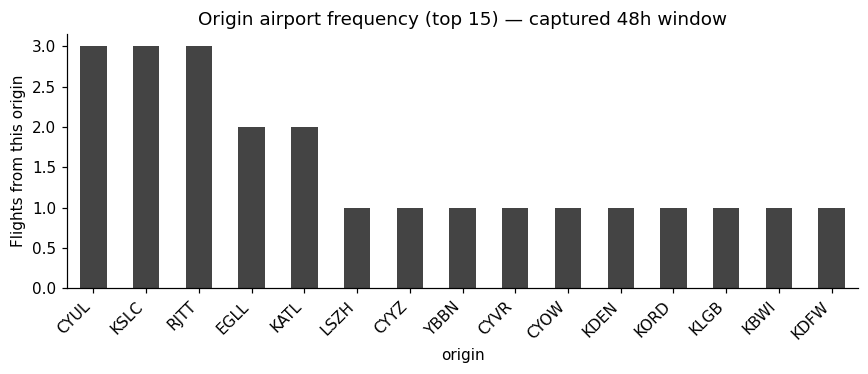

In [9]:
# Origin diversity: which airports appear most often?
origin_counts = flights_df["origin"].fillna("???").value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
origin_counts.head(15).plot(kind="bar", ax=ax, color="#444")
ax.set_ylabel("Flights from this origin")
ax.set_title("Origin airport frequency (top 15) — captured 48h window")
plt.xticks(rotation=45, ha="right")
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

## 4. Ownership ingestion: activating the surface DESIGN §2 promised

DESIGN §2 specifies a two-source ownership consensus (airfleets primary 0.80, Planespotters secondary 0.75, airline press 1.00, manual review 0.95) that resolves into the `ownership_history` materialized view. Until v1.5 wires up the airfleets and Planespotters collectors, no ownership observations exist anywhere in the system — the `observations` table is empty.

This cell closes that loop with what we have: OpenSky's metadata endpoint, already used by Pass 2 above, treated as a ToS-clean substitute ownership source. Confidence is 0.70 — slightly below Planespotters' 0.75 because OpenSky's metadata is community-edited rather than fleet-tracker editorial. (airfleets.net's robots.txt blocks ClaudeBot and signals `ai-train=no`, so a live airfleets collector is deliberately deferred.)

Each verified tail from Pass 2 becomes one observation row, with the OpenSky metadata URL as `source_url` and the owner entity stitched into `notes` (the immutable observations log doesn't carry an `owner_entity` column — that's reconstructed downstream into `ownership_history`).

In [10]:
import tempfile

from fleet_tracker import db
from fleet_tracker.ingest import write_ownership_observation
from fleet_tracker.model import FleetTrackerSource, OwnershipSignal

# Owner entity per verified tail. Both AC and DL operate the tails directly,
# so all eight are OWNED. Lessor-held tails would carry signal=LEASED_IN with
# the lessor entity in owner_entity (e.g. 'AerCap'); none in this seed.
OWNERS = {
    'C-FNOG': ('Air Canada', OwnershipSignal.OWNED),
    'C-FIVK': ('Air Canada', OwnershipSignal.OWNED),
    'C-GFAH': ('Air Canada', OwnershipSignal.OWNED),
    'C-GROV': ('Air Canada', OwnershipSignal.OWNED),
    'N301DU': ('Delta Air Lines', OwnershipSignal.OWNED),
    'N501DN': ('Delta Air Lines', OwnershipSignal.OWNED),
    'N802NW': ('Delta Air Lines', OwnershipSignal.OWNED),
    'N512DN': ('Delta Air Lines', OwnershipSignal.OWNED),
}

demo_db = Path(tempfile.mkdtemp()) / 'fleet_demo.duckdb'

conn = db.connect(demo_db)
db.init_schema(conn)

ids = []
for _, r in verified.iterrows():
    entity, signal = OWNERS[r.tail_number]
    obs_id = write_ownership_observation(
        conn,
        tail_number=r.tail_number,
        owner_entity=entity,
        signal=signal,
        source=FleetTrackerSource.OPENSKY_LIVE,
        source_url=f'https://opensky-network.org/api/metadata/aircraft/icao/{r.opensky_icao24}',
        confidence=0.70,
        notes='OpenSky metadata cross-check 2026-05-05',
    )
    ids.append(obs_id)

print(f'Wrote {len(ids)} ownership observations to {demo_db}')
print()

obs_back = conn.sql('''
    SELECT tail_number,
           signal_value AS ownership,
           ROUND(confidence, 2) AS conf,
           source,
           SPLIT_PART(notes, ';', 1) AS owner_entity
    FROM observations
    WHERE signal_kind = 'ownership'
    ORDER BY tail_number
''').df()
obs_back

Wrote 8 ownership observations to /var/folders/w4/4jwlj7s96pn1fmqgx68kk84h0000gn/T/tmpaf_kotmx/fleet_demo.duckdb



,tail_number,ownership,conf,source,owner_entity
0,C-FIVK,owned,0.7,opensky_live,owner_entity=Air Canada
1,C-FNOG,owned,0.7,opensky_live,owner_entity=Air Canada
2,C-GFAH,owned,0.7,opensky_live,owner_entity=Air Canada
3,C-GROV,owned,0.7,opensky_live,owner_entity=Air Canada
4,N301DU,owned,0.7,opensky_live,owner_entity=Delta Air Lines
5,N501DN,owned,0.7,opensky_live,owner_entity=Delta Air Lines
6,N512DN,owned,0.7,opensky_live,owner_entity=Delta Air Lines
7,N802NW,owned,0.7,opensky_live,owner_entity=Delta Air Lines


## 5. Two signal kinds, not two ownership sources

Pass 4 wrote per-tail ownership observations (`signal_kind='ownership'`) from OpenSky metadata at confidence 0.70. The OpenSky API returns per-icao24 records that name the tail directly — the source URL goes to a page about that specific aircraft, so the `ownership` kind is honest.

Wikipedia airline-fleet articles are different. They list aircraft by *type* with seat configs and fleet counts ("Air Canada operates 42 A220-300s with 12J/125Y") but do not name individual tails. If we wrote those into the observations table as `signal_kind='ownership'` rows pointing at the Wikipedia URL, a reviewer following the URL for C-FBOM would land on a page that doesn't say C-FBOM anywhere — the schema's "every observation links to a source URL" promise would be technically met but semantically weakened.

Per DESIGN §6, Wikipedia rows go into a distinct kind: `signal_kind='fleet_membership'`, with `signal_value` carrying the confirmed `aircraft_type` and the operator stitched into `notes`. The downstream `ownership_history` projection ignores `fleet_membership` rows entirely; they're a sanity-check signal ("does this tail's airline+type combination appear in any public fleet listing?"), not an ownership claim.

The display below shows both kinds side-by-side so the contrast is visible — same observations table, two distinct semantics. AC tails get one row of each kind; DL tails carry only the OpenSky `ownership` row (Wikipedia DL fixture is future work). Wikipedia article text is licensed CC-BY-SA-4.0; the captured fixture in `tests/fixtures/wikipedia_ac_fleet.html` carries attribution in its header.

In [11]:
from fleet_tracker.collectors import wikipedia_fleet

# Parse the captured Wikipedia AC fleet fixture. Live fetch via
# wikipedia_fleet.fetch_fleet_html('ac') also works (with day-keyed cache),
# but the fixture keeps this notebook reproducible offline.
ac_fixture = ROOT / 'tests' / 'fixtures' / 'wikipedia_ac_fleet.html'
ac_wiki_rows = wikipedia_fleet.parse_current_fleet(ac_fixture.read_text())
print(f'Parsed {len(ac_wiki_rows)} rows from Wikipedia AC fleet article.')

wiki_summary = pd.DataFrame([
    {
        'aircraft_type': r.aircraft_type,
        'in_service': r.in_service,
        'orders': r.orders,
        'seats_J': r.seats_business,
        'seats_W': r.seats_premium,
        'seats_Y': r.seats_economy,
        'seats_total': r.seats_total,
    }
    for r in ac_wiki_rows
])
wiki_summary

Parsed 17 rows from Wikipedia AC fleet article.


,aircraft_type,in_service,orders,seats_J,seats_W,seats_Y,seats_total
0,Airbus A220-300,42.0,23.0,12.0,NaN,125.0,137.0
1,Airbus A320-200,16.0,2.0,12.0,NaN,132.0,146.0
2,Airbus A321-200,16.0,13.0,NaN,16.0,180.0,196.0
3,Airbus A321-200,5.0,13.0,NaN,8.0,176.0,184.0
4,Airbus A321XLR,1.0,29.0,14.0,NaN,168.0,182.0
5,Airbus A330-300,20.0,NaN,32.0,24.0,241.0,297.0
6,Airbus A330-300,20.0,NaN,NaN,30.0,255.0,285.0
7,Airbus A350-1000,NaN,8.0,NaN,NaN,NaN,NaN
8,Boeing 737 MAX 8,51.0,NaN,16.0,NaN,153.0,169.0
9,Boeing 737 MAX 8,51.0,NaN,NaN,NaN,189.0,189.0


In [12]:
# For each verified AC seed tail, find its Wikipedia type row and write a
# fleet_membership observation alongside the OpenSky ownership row in the
# same demo_db. The two kinds remain DISTINCT in the observations table —
# the source URL on a fleet_membership row goes to the Wikipedia AC fleet
# page (which doesn't mention any specific tail), and the row is attached
# to its tail by aircraft_type match in the seed CSV.
from fleet_tracker.ingest import write_fleet_membership_observation

WIKI_AC_URL = wikipedia_fleet.page_url('ac')
seed_airline = dict(zip(fleet['tail_number'], fleet['airline']))
seed_type_for = dict(zip(fleet['tail_number'], fleet['aircraft_type']))

wiki_written = []
for tail in verified['tail_number']:
    if seed_airline.get(tail) != 'AC':
        continue
    seed_type = seed_type_for[tail]
    matches = wikipedia_fleet.find_rows_for_type(ac_wiki_rows, seed_type)
    if not matches:
        print(f'  {tail}: seed type {seed_type!r} not in Wikipedia AC fleet — skipped')
        continue
    obs_id = write_fleet_membership_observation(
        conn,
        tail_number=tail,
        airline='Air Canada',
        aircraft_type=matches[0].aircraft_type,
        source=FleetTrackerSource.WIKIPEDIA_FLEET,
        source_url=WIKI_AC_URL,
        confidence=0.65,
    )
    wiki_written.append(obs_id)

print(f'Wrote {len(wiki_written)} Wikipedia fleet_membership observations.')
print()

# Both kinds, side-by-side. The signal_kind column is the load-bearing
# distinction: ownership rows are per-tail, fleet_membership rows are
# type-level. AC tails get one row of each kind; DL tails carry only the
# OpenSky ownership row in this notebook.
combined = conn.sql('''
    SELECT tail_number,
           signal_kind,
           source,
           ROUND(confidence, 2) AS conf,
           signal_value
    FROM observations
    ORDER BY tail_number, signal_kind
''').df()
combined

Wrote 4 Wikipedia fleet_membership observations.



,tail_number,signal_kind,source,conf,signal_value
0,C-FIVK,fleet_membership,wikipedia_fleet,0.65,Boeing 777-300ER
1,C-FIVK,ownership,opensky_live,0.70,owned
2,C-FNOG,fleet_membership,wikipedia_fleet,0.65,Boeing 787-9
3,C-FNOG,ownership,opensky_live,0.70,owned
4,C-GFAH,fleet_membership,wikipedia_fleet,0.65,Airbus A330-300
5,C-GFAH,ownership,opensky_live,0.70,owned
6,C-GROV,fleet_membership,wikipedia_fleet,0.65,Airbus A220-300
7,C-GROV,ownership,opensky_live,0.70,owned
8,N301DU,ownership,opensky_live,0.70,owned
9,N501DN,ownership,opensky_live,0.70,owned


## 6. Reference roster drift: type-level audit of the seed against Wikipedia

Pass 5 stood up two distinct signal kinds in the same observations table. This pass is the first downstream consumer of `signal_kind='fleet_membership'` — without one, the schema split is just plumbing.

The seed CSVs in `data/reference/` are hand-curated and intentionally a small subset of each carrier's full fleet (Phase 4 expands AC to the full 216-tail and DL to the full 987-tail rosters). The audit answers a narrow but real question: **for the airline types we already cover, does the seed reflect Wikipedia's current-fleet table?** Two buckets matter:

- `unrepresented_in_seed` — types Wikipedia lists in service that the seed has zero tails of. These are the gaps to fill first as the seed grows.
- `seed_types_missing_from_wikipedia` — types in the seed that Wikipedia does not list as in service. Implies a seed typo, a retired type still in the seed, or Wikipedia lagging reality. Either way: investigate manually.

Per-type tail-count deltas are deliberately *not* surfaced. The seed is a subset by design, so deltas always exist; including them would turn the report into noise without changing any decision.

Note this is a different audit from Pass 2: that one is **tail-level** (does each seed icao24 match what OpenSky says about that aircraft?), and this one is **type-level** (does the type roster Wikipedia lists match the type roster the seed covers?). Different sources, different granularities, both worth running.

In [ ]:
from fleet_tracker.audit import (
    diff_seed_against_wikipedia,
    format_drift_report,
)

# Reuse ac_wiki_rows parsed from the captured fixture in Pass 5; same
# input the audit module's CLI would use after fetch_fleet_html('ac').
ac_drift = diff_seed_against_wikipedia(
    seed_csv_path=REFERENCE / 'ac-mainline.csv',
    fleet_rows=ac_wiki_rows,
)
print(format_drift_report('ac', ac_drift))

## What this exercises

- Real OpenSky data via the v1 collector (cache layer working)
- Seed-CSV cross-validation against an authoritative external source (data-quality audit pattern)
- Pandas + matplotlib over the cache JSONs (the v1 read pattern; v1.5 will swap to DuckDB-over-Parquet without changing the analysis surface)
- The ingestion path from collector output to `observations` table (DESIGN §2's ownership surface, activated for the first time)
- Two distinct signal kinds in the same table: `ownership` (per-tail, OpenSky 0.70) and `fleet_membership` (type-level, Wikipedia 0.65). The kinds carry different semantics and feed different downstream views per DESIGN §6.
- The first downstream consumer of `signal_kind='fleet_membership'`: a type-level seed-vs-Wikipedia drift audit (`fleet_tracker.audit`). The schema split earns its keep when a real consumer reads it.

## What v1.5 will add

- Nightly accumulation lets the activity window grow from 48h to multi-month
- DuckDB query layer over the Hive-partitioned Parquet for cheap aggregates
- The retrofit module's `install_rate` rollup, once cabin observations are flowing
- A real airfleets / Planespotters per-tail ownership collector once a ToS-clean integration path is in place; the OpenSky-metadata + Wikipedia type-level signals used here are v1 expedients
- Per-tail route maps via the Winkel-tripel SVG renderer (DESIGN §5)